In [1]:
import io
import yfinance as yf
import requests
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import math
import pickle
from datetime import datetime


In [2]:
def time_elapsed(start_time, end_time):
    if not isinstance(start_time, datetime) or not isinstance(end_time, datetime):
        return None
    elapsed_time = end_time - start_time
    return elapsed_time.days  # Return the number of days

In [3]:
# Official Nasdaq Trader directories for NASDAQ and NYSE-listed stocks.
NASDAQ_LIST_URL = 'https://www.nasdaqtrader.com/dynamic/SymDir/nasdaqlisted.txt'
NYSE_LIST_URL = 'https://www.nasdaqtrader.com/dynamic/SymDir/otherlisted.txt'
US_DOWNLOAD_BATCH_SIZE = 100
US_MAX_TICKERS = None  # Set a positive number for a small test run.
US_PLOT_LIMIT = 20
FUNDAMENTALS_TICKERS = []  # Optional Yahoo Finance tickers; empty avoids thousands of profile requests.
US_LISTING_SOURCES = [
    ('NASDAQ', NASDAQ_LIST_URL, 'Symbol', None),
    ('NYSE', NYSE_LIST_URL, 'ACT Symbol', 'Exchange'),
]

listing_frames = []
for exchange_name, listing_url, symbol_column, exchange_column in US_LISTING_SOURCES:
    response = requests.get(listing_url, headers={'User-Agent': 'Mozilla/5.0'}, timeout=30)
    response.raise_for_status()
    listings = pd.read_csv(io.BytesIO(response.content), sep='|', skipfooter=1,
                           engine='python', dtype=str)
    listings.columns = [str(column).strip() for column in listings.columns]
    required_columns = {symbol_column, 'Security Name', 'ETF', 'Test Issue'}
    if exchange_column:
        required_columns.add(exchange_column)
    missing_columns = required_columns.difference(listings.columns)
    if missing_columns:
        raise ValueError(f'{exchange_name} listing directory is missing required columns: {sorted(missing_columns)}')

    listings[symbol_column] = listings[symbol_column].fillna('').str.strip()
    listings = listings[
        listings[symbol_column].ne('')
        & listings['ETF'].fillna('').str.strip().str.upper().eq('N')
        & listings['Test Issue'].fillna('').str.strip().str.upper().eq('N')
    ].copy()
    if 'NextShares' in listings.columns:
        listings = listings[~listings['NextShares'].fillna('').str.strip().str.upper().eq('Y')]
    if exchange_column:
        listings = listings[listings[exchange_column].fillna('').str.strip().eq('N')]

    exchange_listings = pd.DataFrame({
        'SYMBOL': listings[symbol_column].str.strip(),
        'COMPANY': listings['Security Name'].fillna('').str.strip(),
        'EXCHANGE': exchange_name,
    })
    listing_frames.append(exchange_listings)

us_universe = pd.concat(listing_frames, ignore_index=True)
us_universe['YAHOO_TICKER'] = us_universe['SYMBOL'].str.replace('.', '-', regex=False)
us_universe = us_universe.drop_duplicates('YAHOO_TICKER').sort_values(
    ['EXCHANGE', 'YAHOO_TICKER']
).reset_index(drop=True)
if US_MAX_TICKERS is not None:
    if US_MAX_TICKERS <= 0:
        raise ValueError('US_MAX_TICKERS must be positive or None')
    us_universe = us_universe.head(US_MAX_TICKERS)
stock_ticker = us_universe['YAHOO_TICKER'].tolist()
us_company_names = dict(zip(us_universe['YAHOO_TICKER'], us_universe['COMPANY']))
us_symbols_by_ticker = dict(zip(us_universe['YAHOO_TICKER'], us_universe['SYMBOL']))
print(f'US symbols selected: {len(stock_ticker)} (NASDAQ and NYSE; ETFs and test issues excluded)')


US symbols selected: 7114 (NASDAQ and NYSE; ETFs and test issues excluded)


In [4]:
# Batch downloads keep requests manageable for the full US universe.
price_frames, download_failures = [], []
for batch_start in range(0, len(stock_ticker), US_DOWNLOAD_BATCH_SIZE):
    ticker_batch = stock_ticker[batch_start:batch_start + US_DOWNLOAD_BATCH_SIZE]
    try:
        batch_data = yf.download(tickers=ticker_batch, start='2009-01-01', auto_adjust=False,
                                 progress=False, threads=5, group_by='column')
    except Exception as exc:
        download_failures.append((ticker_batch, str(exc)))
        print(f'Batch {batch_start // US_DOWNLOAD_BATCH_SIZE + 1} failed: {exc}')
        continue
    if batch_data is None or batch_data.empty:
        download_failures.append((ticker_batch, 'No price data returned'))
        print(f'Batch {batch_start // US_DOWNLOAD_BATCH_SIZE + 1} returned no data')
        continue
    if isinstance(batch_data.columns, pd.MultiIndex):
        if 'Close' in batch_data.columns.get_level_values(0):
            pass
        elif 'Close' in batch_data.columns.get_level_values(1):
            batch_data = batch_data.swaplevel(axis=1).sort_index(axis=1)
        else:
            download_failures.append((ticker_batch, 'Close prices missing'))
            print(f'Batch {batch_start // US_DOWNLOAD_BATCH_SIZE + 1} has no Close column')
            continue
    elif len(ticker_batch) == 1:
        batch_data.columns = pd.MultiIndex.from_product([batch_data.columns, ticker_batch])
    else:
        download_failures.append((ticker_batch, 'Unexpected single-level columns'))
        print(f'Batch {batch_start // US_DOWNLOAD_BATCH_SIZE + 1} has unexpected columns')
        continue
    close_data = batch_data.loc[:, batch_data.columns.get_level_values(0) == 'Close']
    if close_data.empty:
        download_failures.append((ticker_batch, 'No Close price data returned'))
        print(f'Batch {batch_start // US_DOWNLOAD_BATCH_SIZE + 1} has no Close price data')
        continue
    price_frames.append(close_data)
if not price_frames:
    raise RuntimeError('No US price history downloaded; check network and yfinance availability.')
stock_name = pd.concat(price_frames, axis=1)
stock_name = stock_name.loc[:, ~stock_name.columns.duplicated()]
stock_ticker = [t for t in stock_ticker if ('Close', t) in stock_name.columns and stock_name[('Close', t)].notna().any()]
if not stock_ticker:
    raise RuntimeError('No listed US symbol has usable Yahoo Close price history.')
us_company_names = {t: us_company_names[t] for t in stock_ticker}
stock_info = {t: {'longName': name} for t, name in us_company_names.items()}
print(f'Price history available for {len(stock_ticker)} of {len(us_universe)} selected symbols.')
print(f'Failed/empty download batches: {len(download_failures)}')


c:\Users\prasa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\prasa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\prasa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inpl

Price history available for 6644 of 7114 selected symbols.
Failed/empty download batches: 0


In [5]:
print(f'Downloaded {stock_name.shape[0]} trading dates for {len(stock_ticker)} symbols.')
display(stock_name.iloc[-5:, :min(12, stock_name.shape[1])])


Downloaded 4491 trading dates for 6644 symbols.


Price      Close                                                               \
Ticker      AACG   AACI  AACIU   AACIW   AACO AACOU AACOW   AACP AACPR  AACPU   
Date                                                                            
2026-11-03  0.62  10.08  10.14     NaN  10.02  10.2   NaN  10.10  0.15  10.45   
2026-11-04  0.61  10.09  10.14     NaN  10.02  10.2   NaN  10.10  0.15  10.41   
2026-11-05  0.63  10.11  10.14     NaN  10.02  10.2   NaN  10.12  0.15  10.33   
2026-11-06  0.60  10.10  10.14     NaN  10.02  10.2   NaN  10.12  0.16  10.90   
2026-11-09  0.59  10.10  10.14  0.1599  10.05  10.2   NaN  10.12  0.16  10.29   

Price                    
Ticker     AACPW    AAL  
Date                     
2026-11-03   NaN  12.82  
2026-11-04   NaN  13.63  
2026-11-05  0.06  12.93  
2026-11-06   NaN  13.18  
2026-11-09   NaN  14.16

In [6]:
simulation_ticker = stock_ticker[0] if isinstance(stock_ticker, (list, tuple)) else stock_ticker
close_prices = stock_name[('Close', simulation_ticker)].dropna()

In [7]:
display(close_prices)

Date
2009-01-02    5.25
2009-01-05    5.04
2009-01-06    4.84
2009-01-07    4.62
2009-01-08    4.55
              ... 
2026-11-03    0.62
2026-11-04    0.61
2026-11-05    0.63
2026-11-06    0.60
2026-11-09    0.59
Name: (Close, AACG), Length: 4491, dtype: float64

In [8]:
# Total growth = last price / first price
total_growth = close_prices.iloc[-1] / close_prices.iloc[0]

In [9]:
print(total_growth)

0.11238094738551549


In [10]:
# Current price / first record (e.g., price at the beginning of 2009)
# provides us with the total growth %

# Next, we want to annualize this percentage
# First, we convert our time elapsed to the number of years elapsed
number_of_days = time_elapsed(stock_name.index[0], stock_name.index[-1])
number_of_years = number_of_days / 365.0  # Assuming 365 days per year

In [11]:
print(number_of_days)
print(number_of_years)

6520
17.863013698630137


In [12]:
print(stock_name.index[0])
print(stock_name.index[-1])

2009-01-02 00:00:00
2026-11-09 00:00:00


In [13]:
simulation_ticker = stock_ticker[0]
close_prices = stock_name[('Close', simulation_ticker)].dropna()
elapsed_years = (close_prices.index[-1] - close_prices.index[0]).days / 365.25
if close_prices.empty or elapsed_years <= 0:
    raise ValueError(f'Cannot calculate historical growth for {simulation_ticker}: insufficient history')
cagr = (close_prices.iloc[-1] / close_prices.iloc[0]) ** (1 / elapsed_years) - 1
std_dev = close_prices.pct_change().std() * math.sqrt(252)
if not np.isfinite(cagr) or not np.isfinite(std_dev):
    raise ValueError(f'Cannot simulate {simulation_ticker}: invalid price history')
number_of_trading_days = 252
daily_return_percentages = np.random.normal(cagr / 252, std_dev / math.sqrt(252), 252) + 1
price_series = [float(close_prices.iloc[-1])]
for daily_return in daily_return_percentages:
    price_series.append(price_series[-1] * daily_return)


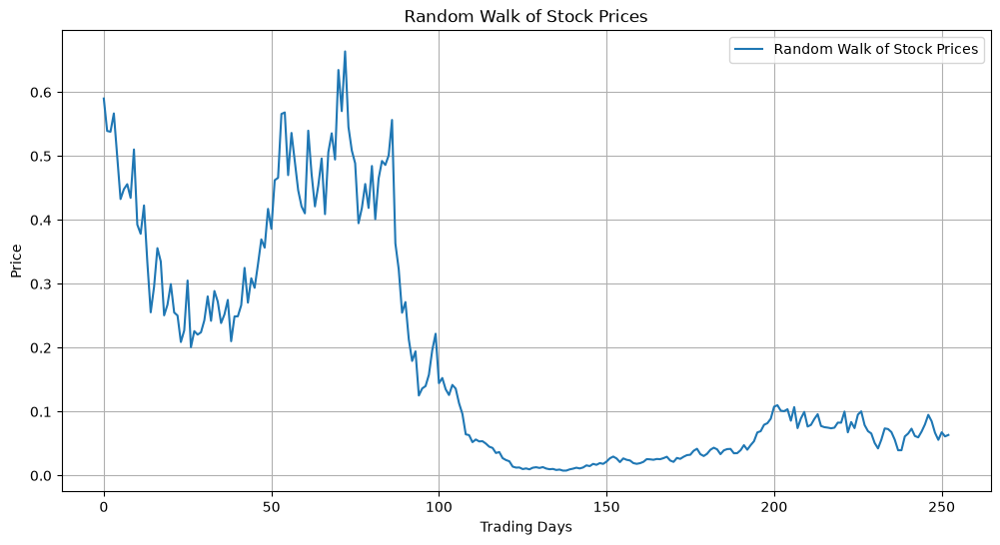

In [14]:
# Plot a single 'random walk' of stock prices
plt.figure(figsize=(12, 6))
plt.plot(price_series, label='Random Walk of Stock Prices')
plt.xlabel('Trading Days')
plt.ylabel('Price')
plt.title('Random Walk of Stock Prices')
plt.legend()
plt.grid(True)
plt.show()

# Now that we've created a single random walk above,
# we can simulate this process over a large sample size to
# get a better seus of the true expected distribution
number_of_trials = 3000

# Set up an additional array to collect all possible
# closing prices on the last day of the window.
# We can use this for a histogram to get a clearer seus of possible outcomes
closing_prices = []


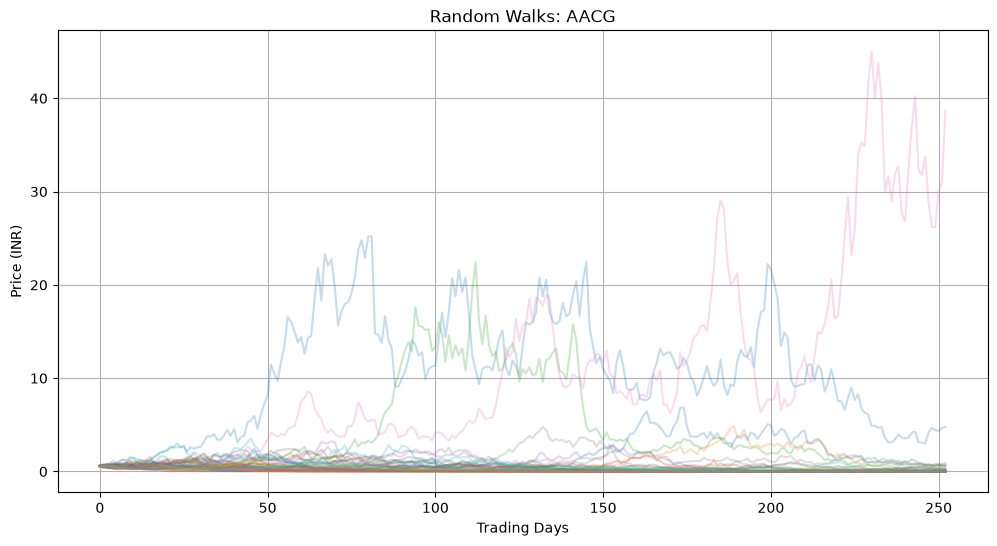

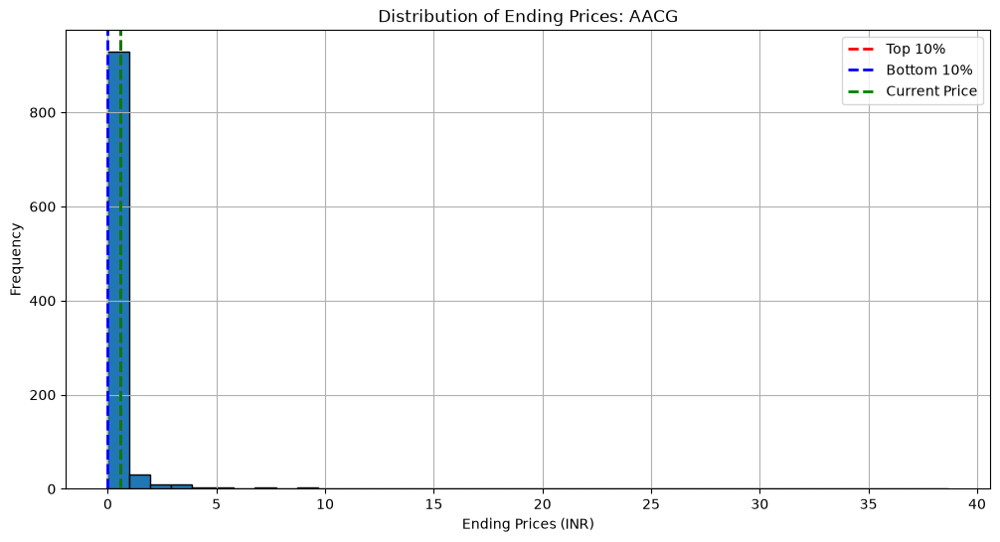

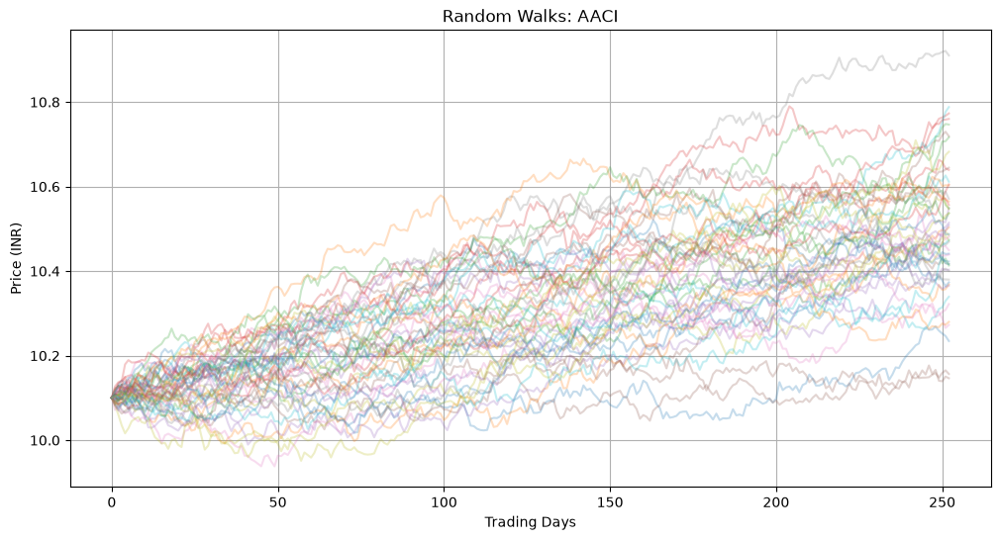

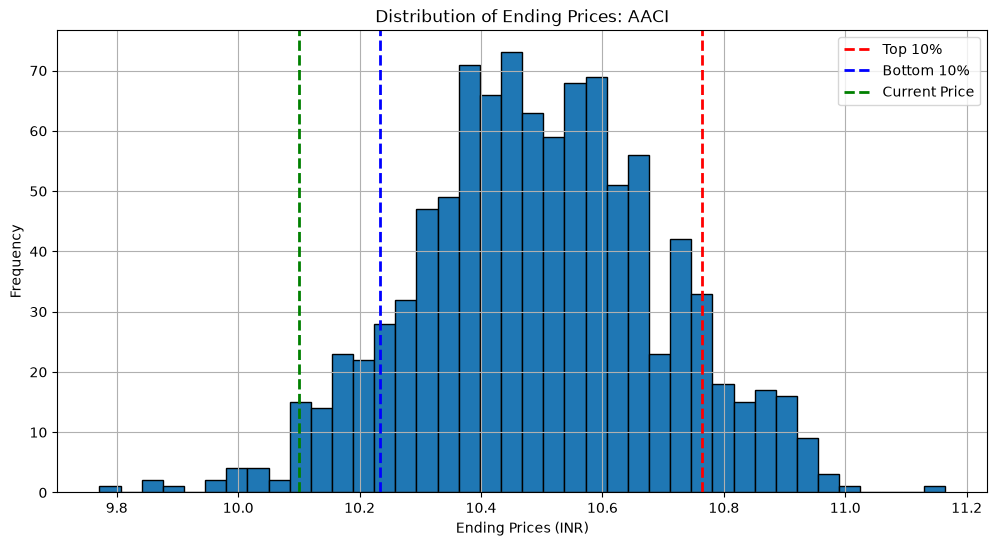

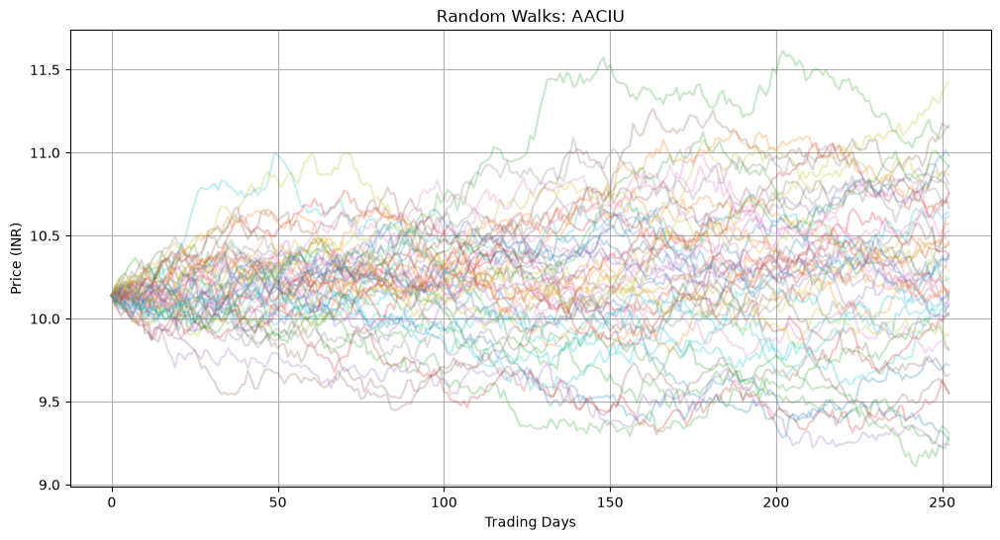

...

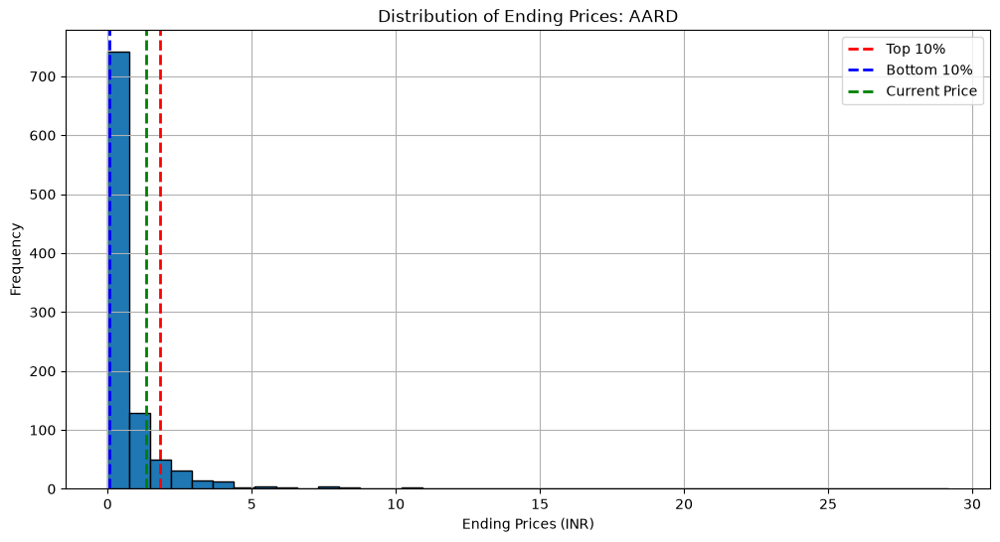

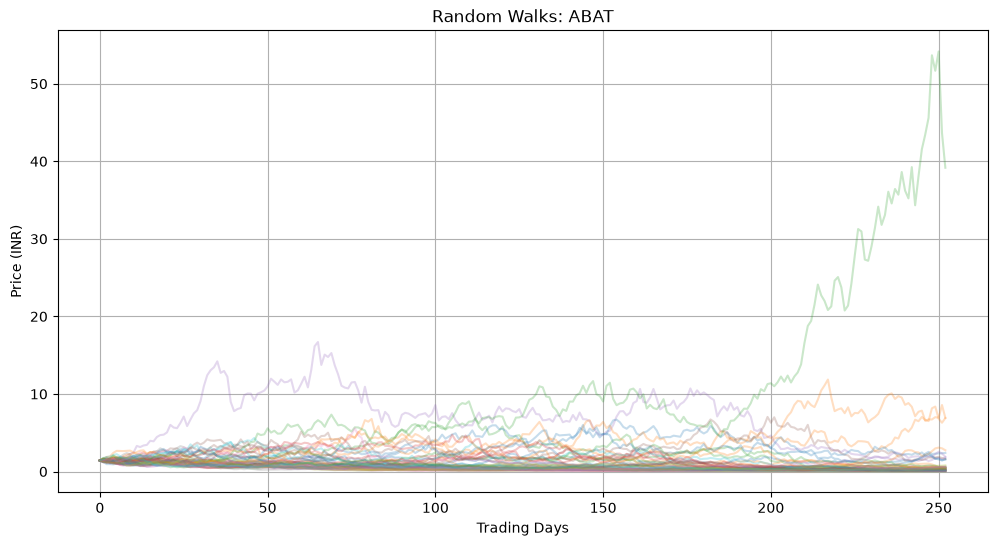

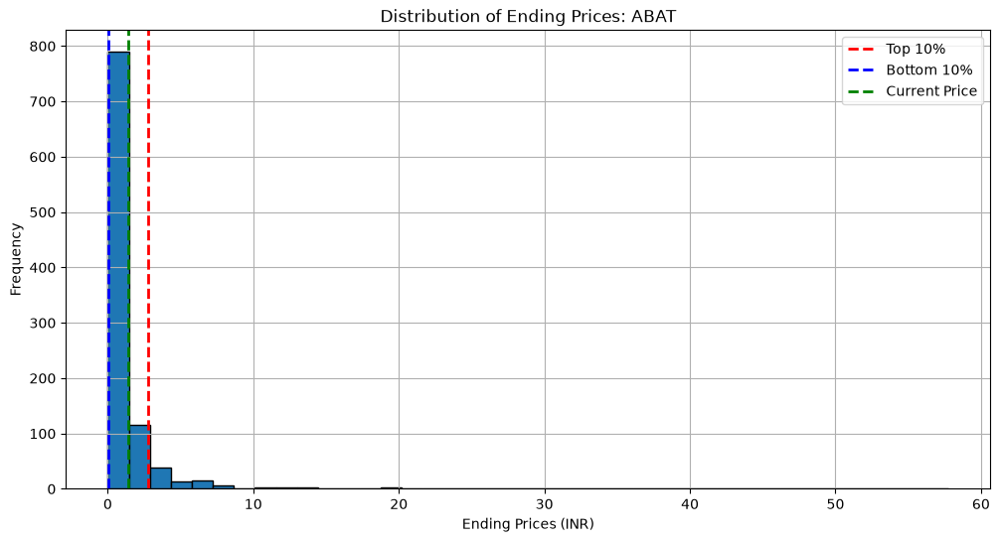

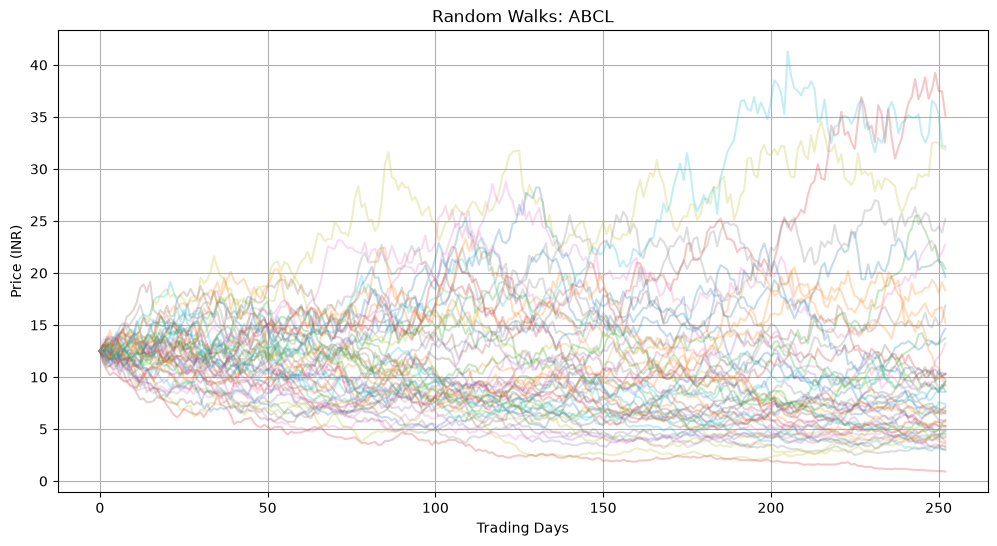

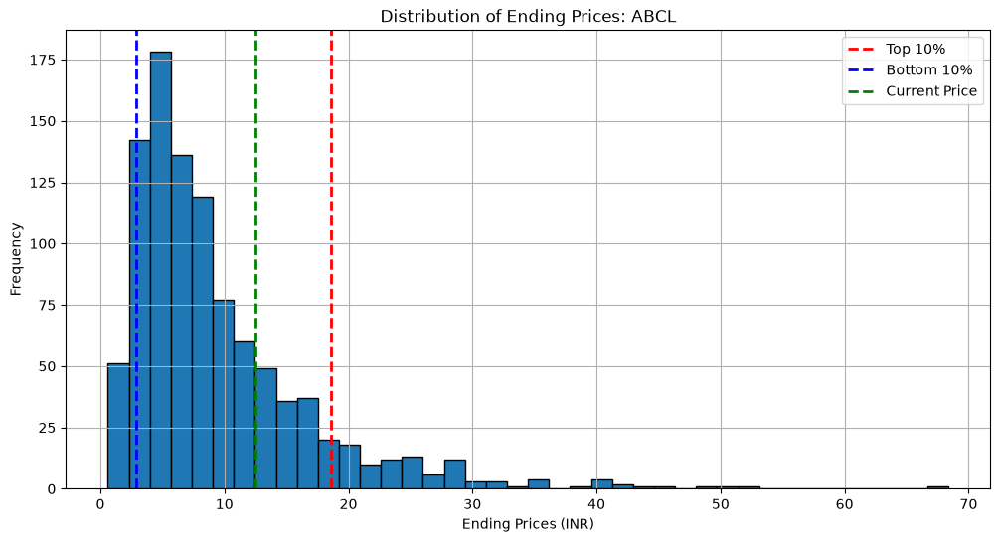

c:\Users\prasa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\numpy\_core\fromnumeric.py:83: RuntimeWarning: overflow encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)


Basic simulations completed: 6128 of 6644 downloaded symbols.
Skipped for insufficient/invalid data: 516


In [15]:
number_of_trials = 1000
number_of_trading_days = 252
minimum_history_days = 60
plot_tickers = set(stock_ticker[:US_PLOT_LIMIT])
simulation_results, skipped_tickers = {}, []
for ticker in stock_ticker:
    series = stock_name[('Close', ticker)].dropna()
    if len(series) < minimum_history_days:
        skipped_tickers.append((ticker, 'less than 60 historical prices'))
        continue
    elapsed_years = (series.index[-1] - series.index[0]).days / 365.25
    if elapsed_years <= 0:
        skipped_tickers.append((ticker, 'invalid date range'))
        continue
    cagr = (series.iloc[-1] / series.iloc[0]) ** (1 / elapsed_years) - 1
    std_dev = series.pct_change().std() * math.sqrt(number_of_trading_days)
    if not np.isfinite(cagr) or not np.isfinite(std_dev):
        skipped_tickers.append((ticker, 'invalid simulation parameters'))
        continue
    daily_factors = np.random.normal(cagr / 252, std_dev / math.sqrt(252),
                                     size=(number_of_trials, number_of_trading_days)) + 1
    closing = float(series.iloc[-1]) * np.prod(daily_factors, axis=1)
    if not np.isfinite(closing).all():
        skipped_tickers.append((ticker, 'non-finite simulated prices'))
        continue
    current = float(series.iloc[-1])
    simulation_results[ticker] = {
        'closing_prices': closing.tolist(), 'mean_end_price': float(np.mean(closing)),
        'top_ten': float(np.percentile(closing, 90)), 'bottom_ten': float(np.percentile(closing, 10)),
        'current_price': current,
    }
    if ticker in plot_tickers:
        plt.figure(figsize=(12, 6))
        for path in current * np.cumprod(daily_factors[:50], axis=1):
            plt.plot(np.r_[current, path], alpha=0.25)
        plt.title(f'Random Walks: {ticker}')
        plt.xlabel('Trading Days')
        plt.ylabel('Price (INR)')
        plt.grid(True)
        plt.show()
        plt.close()
        plt.figure(figsize=(12, 6))
        plt.hist(closing, bins=40, edgecolor='black')
        plt.axvline(np.percentile(closing, 90), color='r', linestyle='dashed', linewidth=2, label='Top 10%')
        plt.axvline(np.percentile(closing, 10), color='b', linestyle='dashed', linewidth=2, label='Bottom 10%')
        plt.axvline(current, color='g', linestyle='dashed', linewidth=2, label='Current Price')
        plt.xlabel('Ending Prices (INR)')
        plt.ylabel('Frequency')
        plt.title(f'Distribution of Ending Prices: {ticker}')
        plt.legend()
        plt.grid(True)
        plt.savefig(f'histogram_{ticker}.png')
        plt.show()
        plt.close()
closing_prices_by_ticker = {t: result['closing_prices'] for t, result in simulation_results.items()}
if not simulation_results:
    raise RuntimeError('No symbols had enough valid data to simulate.')
print(f'Basic simulations completed: {len(simulation_results)} of {len(stock_ticker)} downloaded symbols.')
print(f'Skipped for insufficient/invalid data: {len(skipped_tickers)}')


In [16]:
data_to_pickle = {
    'universe': stock_ticker,
    'company_names': us_company_names,
    'simulation_results': simulation_results,
}
pickle_file_path = 'us_stock_simulation_data.pkl'
with open(pickle_file_path, 'wb') as pickle_file:
    pickle.dump(data_to_pickle, pickle_file)
print(f'Data has been saved to {pickle_file_path}')


Data has been saved to us_stock_simulation_data.pkl


In [17]:
target_date = stock_name.index[-1] + pd.tseries.offsets.BDay(252)
basic_projection_table = pd.DataFrame.from_dict(simulation_results, orient='index')
basic_projection_table.index.name = 'yahoo_ticker'
basic_projection_table['company'] = [us_company_names[t] for t in basic_projection_table.index]
basic_projection_table['projected_return_pct'] = (basic_projection_table['mean_end_price'] / basic_projection_table['current_price'] - 1) * 100
print('Last available data date:', stock_name.index[-1].date())
print('1-year projection date:', target_date.date())
print(f'Projection results for {len(basic_projection_table)} symbols; displaying the 15 highest projected returns.')
display(basic_projection_table.sort_values('projected_return_pct', ascending=False).head(15))


Last available data date: 2026-11-09
1-year projection date: 2027-10-27
Projection results for 6128 symbols; displaying the 15 highest projected returns.


,closing_prices,mean_end_price,top_ten,bottom_ten,current_price,company,projected_return_pct
yahoo_ticker,,,,,,,
OGG,[761043852590394718254887737143326157706970732...,5.309864e+246,5.584195e+229,-3.698110e+230,2.670000,Osisko Gold Group Inc. Common Shares,1.988713e+248
HYFT,[840213462175774065483160514682930296848164540...,1.124562e+231,8.823152e+217,-2.275315e+218,1.080000,MindWalk Holdings Corp. - Common Stock,1.041261e+233
JXG,[457035666030140896027283555122480200602865769...,6.952017e+178,1.263958e+155,-5.745066e+154,9.850000,JX Luxventure Group Inc. - Common Stock,7.057885e+179
LICN,[-19521558906516052906167895104890657519710024...,6.886010e+125,8.293444e+113,-8.404170e+113,0.305000,Lichen International Limited - Class A Ordinar...,2.257708e+128
AMPY,"[3412496208081856198700402092417413545984.0, 2...",1.295549e+64,2.604309e+53,-1.304308e+52,3.200000,Amplify Energy Corp. Common Stock,4.048590e+65
ATXG,"[59937450.901269, -73820877201960271872.0, -35...",6.456292e+32,1.786741e+20,-7.123472e+20,2.560000,Addentax Group Corp. - Common Stock,2.521989e+34
VCIG,"[-0.013948, -0.0, -0.003344, -92.196298, 11140...",2.237190e+19,1.772613e+09,-7.264011e+07,6.660000,VCI Global Limited - Ordinary Share,3.359144e+20
USDEW,"[5144270844525050.0, 38312785407610688.0, 1145...",6.494072e+17,1.030303e+18,1.243482e+15,2.070000,StablecoinX Inc. - Warrants,3.137233e+19
AMTD,"[0.0, -15017678535.730185, -313459.650036, -0....",1.516428e+14,6.800431e+01,-1.619824e+01,13.400000,"AMTD IDEA Group American Depositary Shares, ea...",1.131663e+15


# US-wide Monte Carlo projections with optional analyst enrichment

The universe is built from the official Nasdaq Trader NASDAQ and NYSE symbol directories. ETFs and test issues are excluded, and US symbols are mapped to Yahoo Finance ticker format. Every selected symbol with usable Yahoo price history is simulated; symbols without data or at least 60 price observations are skipped and counted.

Historical price data drives both models. Analyst targets and fundamentals are fetched only for symbols explicitly listed in `FUNDAMENTALS_TICKERS` in the setup cell, avoiding thousands of rate-limited profile requests. Without analyst data, enhanced drift falls back to historical CAGR.

Plots are limited to `US_PLOT_LIMIT` symbols by default. Set `US_MAX_TICKERS` for a smaller test run.

In [18]:
# Find technical-screen candidates first, then request analyst targets only for those symbols.
def build_positive_momentum_rows():
    rows = []
    for ticker_symbol in stock_ticker:
        close_series = stock_name[('Close', ticker_symbol)].dropna().sort_index()
        if len(close_series) < 50:
            continue

        latest_date = close_series.index[-1]
        year_start = pd.Timestamp(year=latest_date.year, month=1, day=1, tz=latest_date.tz)
        three_month_start = latest_date - pd.DateOffset(months=3)
        prior_year_close = close_series.loc[close_series.index < year_start]
        if prior_year_close.empty:
            year_to_date_prices = close_series.loc[close_series.index >= year_start]
            if year_to_date_prices.empty:
                continue
            ytd_start_price = float(year_to_date_prices.iloc[0])
        else:
            ytd_start_price = float(prior_year_close.iloc[-1])

        three_month_prices = close_series.loc[close_series.index <= three_month_start]
        if three_month_prices.empty or ytd_start_price <= 0:
            continue
        three_month_start_price = float(three_month_prices.iloc[-1])
        current_price = float(close_series.iloc[-1])
        if three_month_start_price <= 0:
            continue

        ema_9 = close_series.ewm(span=9, adjust=False, min_periods=9).mean().iloc[-1]
        ema_20 = close_series.ewm(span=20, adjust=False, min_periods=20).mean().iloc[-1]
        ema_50 = close_series.ewm(span=50, adjust=False, min_periods=50).mean().iloc[-1]
        ytd_return = current_price / ytd_start_price - 1
        three_month_return = current_price / three_month_start_price - 1

        if ytd_return > 0 and three_month_return > 0 and ema_9 > ema_20 > ema_50:
            us_symbol = us_symbols_by_ticker.get(ticker_symbol, ticker_symbol)
            rows.append({
                'yahoo_ticker': ticker_symbol,
                'us_symbol': us_symbol,
                'company': us_company_names.get(ticker_symbol, us_symbol),
                'as_of': latest_date.date(),
                'current_price': current_price,
                'ytd_return_pct': ytd_return * 100,
                'three_month_return_pct': three_month_return * 100,
                'ema_9': float(ema_9),
                'ema_20': float(ema_20),
                'ema_50': float(ema_50),
            })
    return rows

positive_momentum_rows = build_positive_momentum_rows()
positive_momentum_tickers = [row['yahoo_ticker'] for row in positive_momentum_rows]
selected_fundamentals_tickers = [t for t in FUNDAMENTALS_TICKERS if t in stock_ticker]
analyst_target_tickers = sorted(set(selected_fundamentals_tickers) | set(positive_momentum_tickers))
fundamentals_by_ticker = {t: {} for t in stock_ticker}
for ticker_symbol in analyst_target_tickers:
    try:
        info = yf.Ticker(ticker_symbol).info
        fundamentals_by_ticker[ticker_symbol] = {
            key: info.get(key) for key in (
                'currentPrice', 'targetMeanPrice', 'targetMedianPrice', 'targetHighPrice',
                'targetLowPrice', 'recommendationKey', 'numberOfAnalystOpinions',
                'trailingPE', 'forwardPE', 'trailingEps', 'forwardEps', 'earningsGrowth',
                'revenueGrowth', 'beta', 'marketCap',
            )
        }
        print(f'Fetched profile and analyst data for {ticker_symbol}')
    except Exception as exc:
        print(f'Could not fetch fundamentals for {ticker_symbol}: {exc}')
print(f'Fundamentals fetched for {sum(bool(v) for v in fundamentals_by_ticker.values())} symbols.')
print(f'Analyst target lookup requested for {len(analyst_target_tickers)} symbols, including {len(positive_momentum_tickers)} momentum-screen candidates.')
fundamentals = fundamentals_by_ticker


Fetched profile and analyst data for A
Fetched profile and analyst data for AACI
Fetched profile and analyst data for AACO
Fetched profile and analyst data for AACOU
Fetched profile and analyst data for AACP
Fetched profile and analyst data for AACPU
Fetched profile and analyst data for AAPL
Fetched profile and analyst data for ABBV
Fetched profile and analyst data for ABLV
Fetched profile and analyst data for ABM
Fetched profile and analyst data for ABNB
Fetched profile and analyst data for ABSI
Fetched profile and analyst data for ACB
Fetched profile and analyst data for ACCO
Fetched profile and analyst data for ACEL
Fetched profile and analyst data for ACGC
Fetched profile and analyst data for ACGL
Fetched profile and analyst data for ACHC
Fetched profile and analyst data for ACIW
Fetched profile and analyst data for ACNB
Fetched profile and analyst data for ADP
Fetched profile and analyst data for ADPT
Fetched profile and analyst data for ADT
Fetched profile and analyst data for AD

In [19]:
eps_trends, growth_estimates_by_ticker = {}, {}
for ticker_symbol in selected_fundamentals_tickers:
    ticker = yf.Ticker(ticker_symbol)
    try:
        eps_trends[ticker_symbol] = ticker.eps_trend
        display(eps_trends[ticker_symbol])
    except Exception as exc:
        print(f'EPS trend unavailable for {ticker_symbol}: {exc}')
        eps_trends[ticker_symbol] = None
    try:
        growth_estimates_by_ticker[ticker_symbol] = ticker.growth_estimates
        display(growth_estimates_by_ticker[ticker_symbol])
    except Exception as exc:
        print(f'Growth estimates unavailable for {ticker_symbol}: {exc}')
        growth_estimates_by_ticker[ticker_symbol] = None
if not selected_fundamentals_tickers:
    print('EPS/growth API calls skipped; add US Yahoo Finance tickers to FUNDAMENTALS_TICKERS to enable them.')


EPS/growth API calls skipped; add US Yahoo Finance tickers to FUNDAMENTALS_TICKERS to enable them.


In [20]:
stock_metrics = {}
for ticker_symbol in stock_ticker:
    close_series = stock_name[('Close', ticker_symbol)].dropna()
    if len(close_series) < minimum_history_days:
        continue
    elapsed_years = (close_series.index[-1] - close_series.index[0]).days / 365.25
    if elapsed_years <= 0:
        continue
    current_price = float(close_series.iloc[-1])
    ticker_cagr = (close_series.iloc[-1] / close_series.iloc[0]) ** (1 / elapsed_years) - 1
    ticker_std_dev = close_series.pct_change().std() * math.sqrt(252)
    recent_std_dev = close_series.tail(504).pct_change().std() * math.sqrt(252)
    if not np.isfinite(recent_std_dev):
        recent_std_dev = ticker_std_dev
    if not np.isfinite(ticker_cagr) or not np.isfinite(ticker_std_dev):
        continue
    analyst_target = fundamentals_by_ticker.get(ticker_symbol, {}).get('targetMeanPrice')
    try:
        analyst_target = float(analyst_target) if analyst_target is not None else None
    except (TypeError, ValueError):
        analyst_target = None
    if analyst_target is not None and (not np.isfinite(analyst_target) or analyst_target <= 0):
        analyst_target = None
    analyst_return = analyst_target / current_price - 1 if analyst_target is not None and current_price > 0 else None
    blended_drift = 0.5 * (ticker_cagr + analyst_return) if analyst_return is not None else ticker_cagr
    stock_metrics[ticker_symbol] = {
        'current_price': current_price, 'cagr': ticker_cagr,
        'analyst_mean_1y': analyst_target, 'analyst_implied_return': analyst_return,
        'blended_drift': blended_drift, 'long_term_volatility': ticker_std_dev,
        'recent_volatility': recent_std_dev,
        'blended_volatility': 0.5 * ticker_std_dev + 0.5 * recent_std_dev,
    }
print(f'Enhanced metrics calculated for {len(stock_metrics)} symbols.')
print(f'Analyst targets available for {sum(m["analyst_mean_1y"] is not None for m in stock_metrics.values())} symbols.')


Enhanced metrics calculated for 6131 symbols.
Analyst targets available for 837 symbols.


In [21]:
enhanced_simulation_results = {}
for ticker_symbol, metrics in stock_metrics.items():
    daily_factors = np.random.normal(
        metrics['blended_drift'] / number_of_trading_days,
        metrics['blended_volatility'] / math.sqrt(number_of_trading_days),
        size=(number_of_trials, number_of_trading_days),
    ) + 1
    closing = metrics['current_price'] * np.prod(daily_factors, axis=1)
    if not np.isfinite(closing).all():
        print(f'Skipping enhanced simulation for {ticker_symbol}: non-finite prices')
        continue
    enhanced_simulation_results[ticker_symbol] = closing.tolist()
if not enhanced_simulation_results:
    raise RuntimeError('No valid enhanced US simulations were produced.')
print(f'Enhanced simulations completed for {len(enhanced_simulation_results)} symbols.')


c:\Users\prasa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\numpy\_core\fromnumeric.py:83: RuntimeWarning: overflow encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)
C:\Users\prasa\AppData\Local\Temp\ipykernel_28936\1399450830.py:8: RuntimeWarning: overflow encountered in multiply
  closing = metrics['current_price'] * np.prod(daily_factors, axis=1)


Skipping enhanced simulation for ABVC: non-finite prices
Skipping enhanced simulation for PPCB: non-finite prices
Enhanced simulations completed for 6129 symbols.


In [22]:
enhanced_projection_summary = {}
projection_date = stock_name.index[-1] + pd.tseries.offsets.BDay(number_of_trading_days)
for ticker_symbol, closing in enhanced_simulation_results.items():
    metrics = stock_metrics[ticker_symbol]
    current_price = metrics['current_price']
    enhanced_projection_summary[ticker_symbol] = {
        'current_price': current_price, 'mean_price': float(np.mean(closing)),
        'p5': float(np.percentile(closing, 5)), 'p25': float(np.percentile(closing, 25)),
        'p50': float(np.percentile(closing, 50)), 'p75': float(np.percentile(closing, 75)),
        'p95': float(np.percentile(closing, 95)),
        'prob_gain': float(np.mean(np.asarray(closing) > current_price)),
        'projection_date': projection_date, 'analyst_mean_1y': metrics['analyst_mean_1y'],
    }
enhanced_projection_table = pd.DataFrame.from_dict(enhanced_projection_summary, orient='index')
enhanced_projection_table.index.name = 'yahoo_ticker'
enhanced_projection_table['us_symbol'] = [us_symbols_by_ticker.get(t, t) for t in enhanced_projection_table.index]
enhanced_projection_table['company'] = [us_company_names.get(t, t) for t in enhanced_projection_table.index]
enhanced_projection_table['projected_return_pct'] = (enhanced_projection_table['mean_price'] / enhanced_projection_table['current_price'] - 1) * 100
print(f'One-year projections completed for {len(enhanced_projection_table)} symbols.')
display(enhanced_projection_table.sort_values('projected_return_pct', ascending=False).head(20))


One-year projections completed for 6129 symbols.


,current_price,mean_price,p5,p25,p50,p75,p95,prob_gain,projection_date,analyst_mean_1y,us_symbol,company,projected_return_pct
yahoo_ticker,,,,,,,,,,,,,
OGG,2.670000,5.938348e+164,-4.096876e+158,-3.990562e+148,7.953046e+133,9.467526e+148,8.462711e+158,0.512,2027-10-27,NaN,OGG,Osisko Gold Group Inc. Common Shares,2.224100e+166
LICN,0.305000,9.581380e+146,-7.175365e+133,-4.586062e+124,-6.317977e+107,4.526490e+124,5.778516e+133,0.495,2027-10-27,NaN,LICN,Lichen International Limited - Class A Ordinar...,3.141436e+149
JXG,9.850000,2.757992e+102,-1.252972e+88,-5.047305e+77,8.726581e+59,6.413049e+78,4.092277e+88,0.502,2027-10-27,NaN,JXG,JX Luxventure Group Inc. - Common Stock,2.799992e+103
DKI,1.540000,6.416284e+83,-2.041792e+73,-2.793530e+62,1.426087e+50,7.377343e+62,8.204025e+71,0.520,2027-10-27,NaN,DKI,DarkIris Inc. - Class A Ordinary Shares,4.166418e+85
AMTD,13.400000,2.025179e+48,-6.652295e+34,-6.493338e+24,-3.380506e+10,3.465869e+23,2.587136e+33,0.480,2027-10-27,NaN,AMTD,"AMTD IDEA Group American Depositary Shares, ea...",1.511328e+49
CHRD,137.490005,1.758256e+42,-6.724512e+30,-2.330981e+22,-1.243258e+06,1.035589e+22,7.459259e+32,0.482,2027-10-27,NaN,CHRD,Chord Energy Corporation - Common Stock,1.278825e+42
INHD,2.640000,5.435712e+19,-4.775607e+07,-1.979646e-02,3.085998e-21,7.271786e-03,6.248636e+06,0.176,2027-10-27,NaN,INHD,Inno Holdings Inc. - Common Stock,2.058982e+21
USDEW,2.070000,1.312367e+18,3.394128e+14,5.587647e+15,3.150117e+16,1.758364e+17,2.712217e+18,1.000,2027-10-27,NaN,USDEW,StablecoinX Inc. - Warrants,6.339937e+19
DFSC,0.558000,1.600358e+15,-1.380724e+03,-7.513747e-07,-2.532237e-26,2.513630e-06,1.944441e+02,0.106,2027-10-27,NaN,DFSC,"DEFSEC Technologies Inc. - common stock, no R/...",2.868025e+17


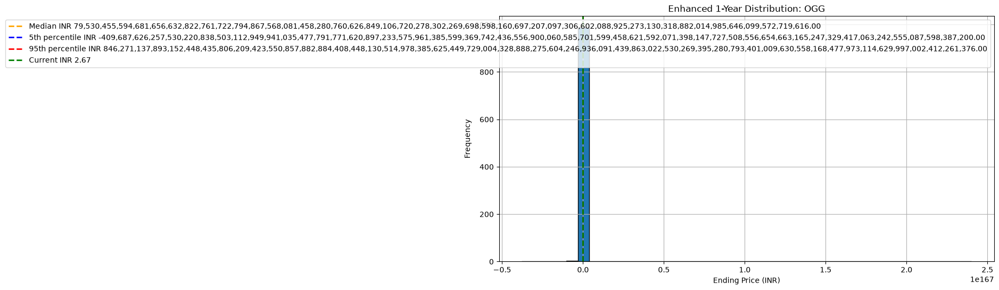

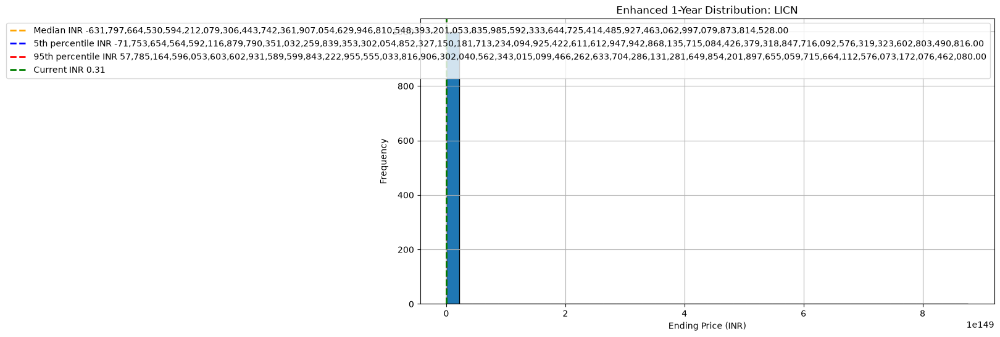

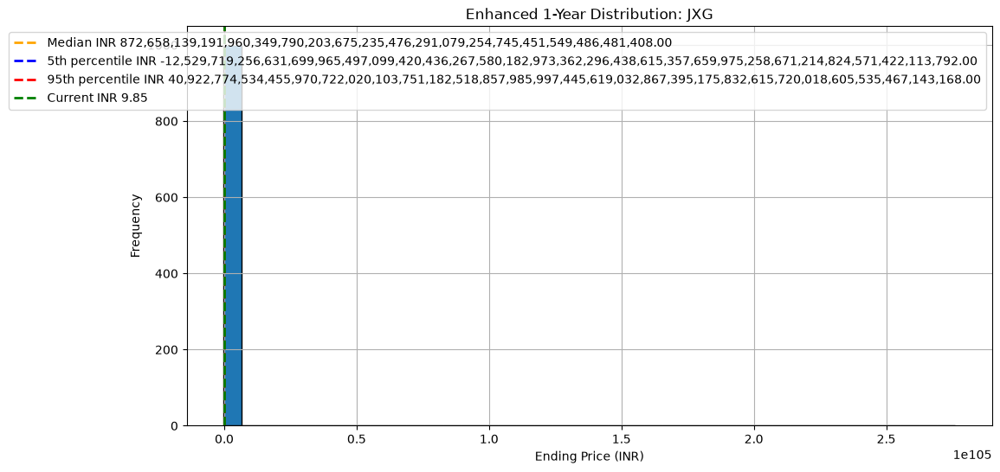

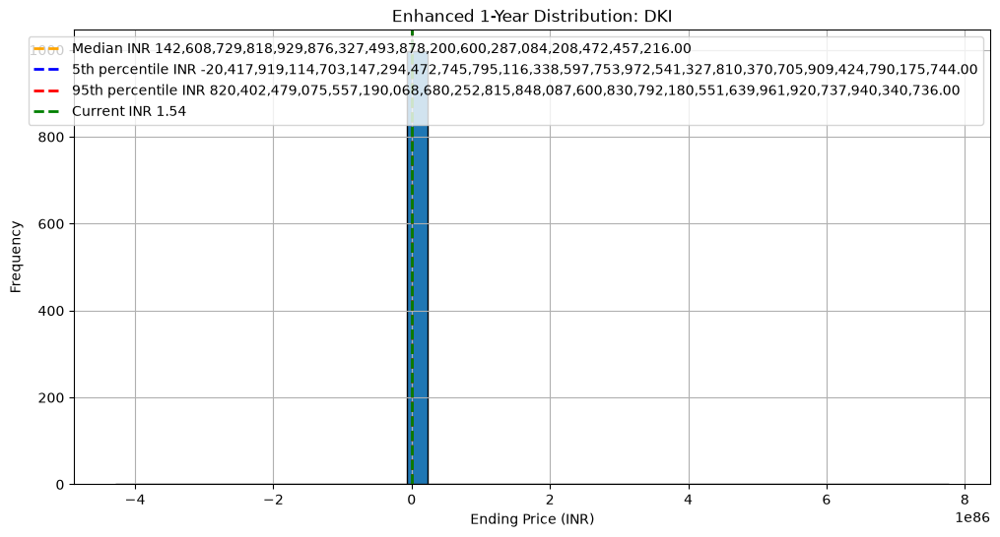

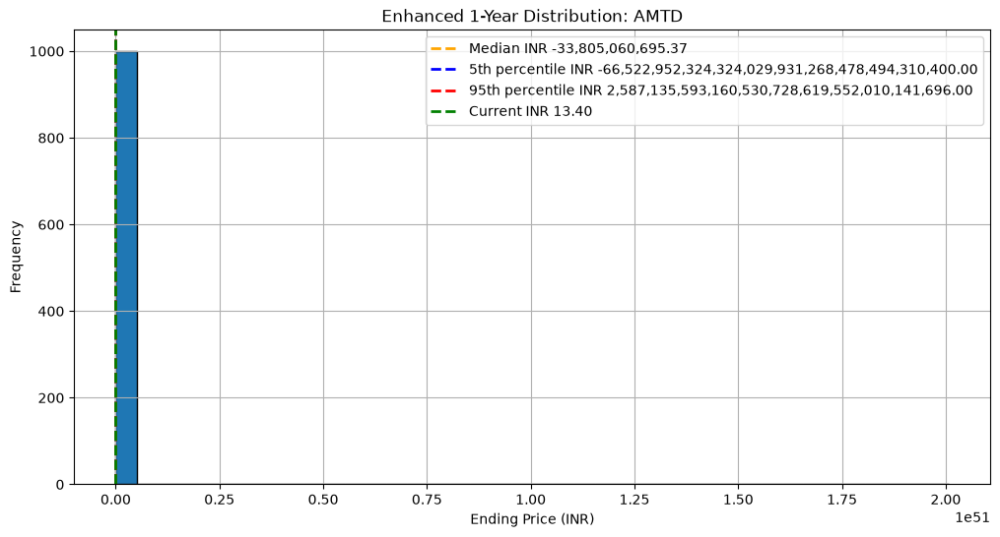

...

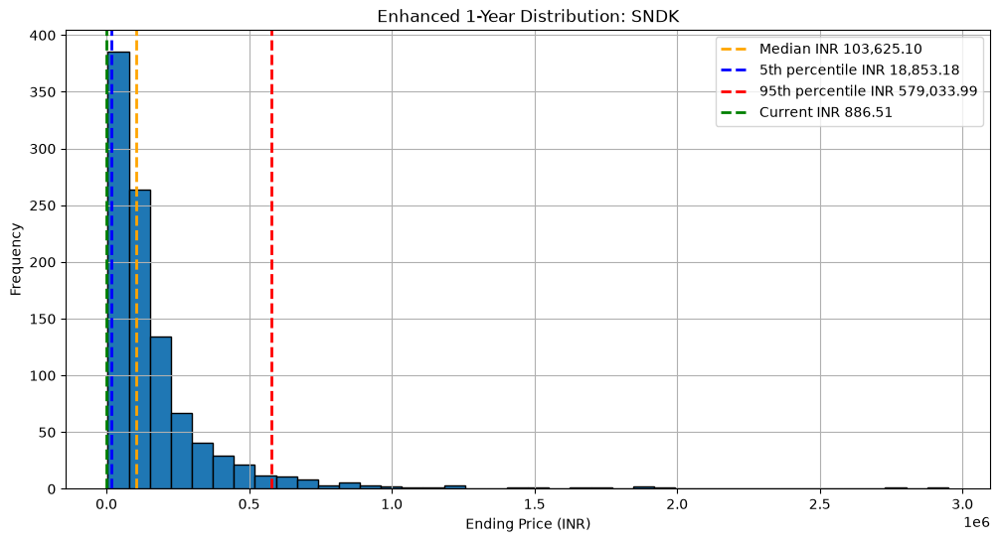

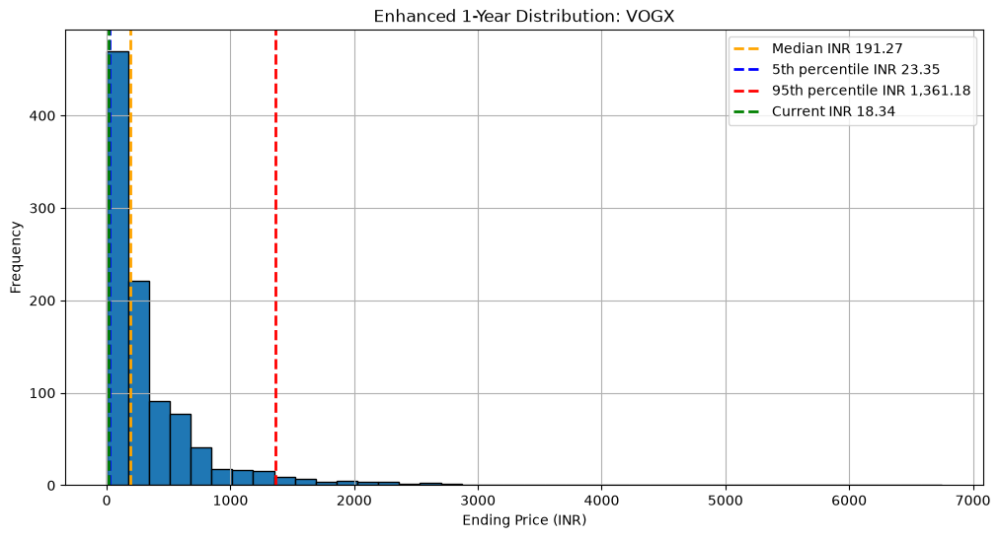

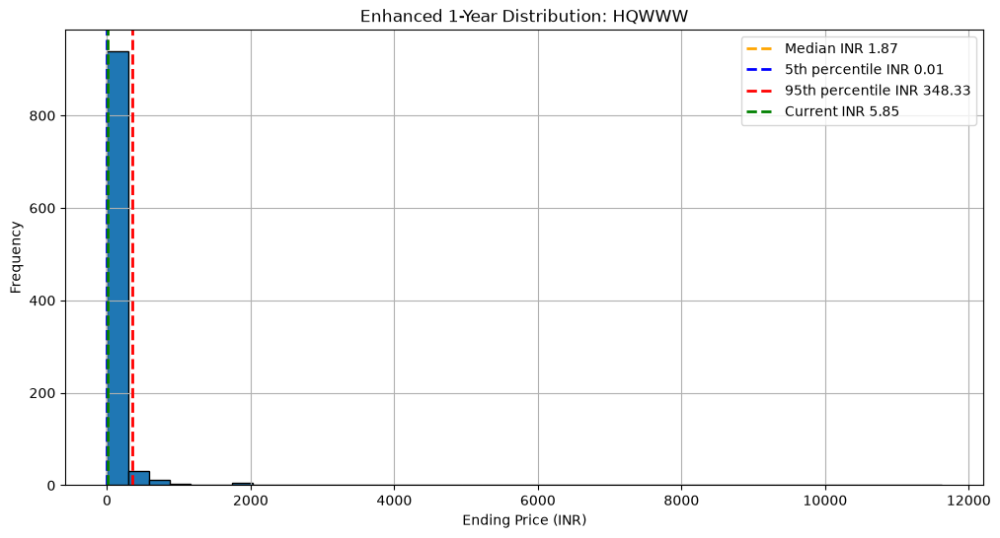

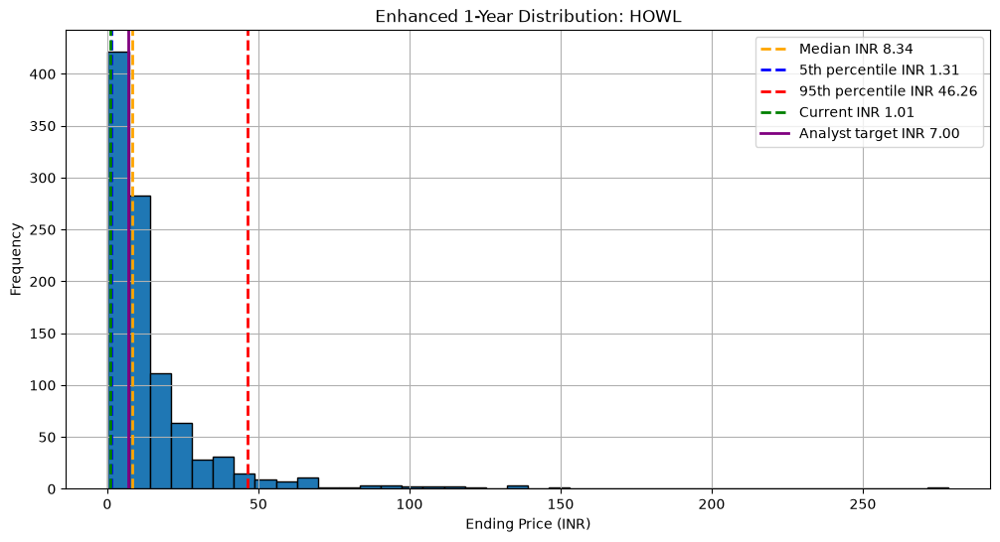

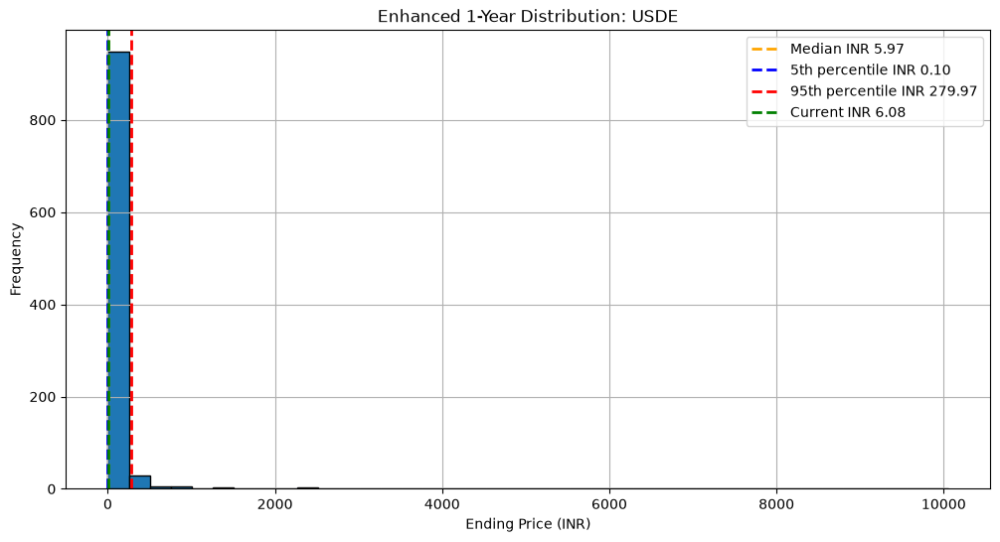

All enhanced results saved to us_enhanced_simulation_data.pkl; plotted 20 symbols.


In [23]:
# Plot a small sample and save all enhanced US results together.
plot_candidates = enhanced_projection_table.sort_values('projected_return_pct', ascending=False).head(US_PLOT_LIMIT).index
for ticker_symbol in plot_candidates:
    prices = enhanced_simulation_results[ticker_symbol]
    summary = enhanced_projection_summary[ticker_symbol]
    plt.figure(figsize=(12, 6))
    plt.hist(prices, bins=40, edgecolor='black')
    plt.axvline(summary['p50'], color='orange', linestyle='dashed', linewidth=2, label=f"Median INR {summary['p50']:,.2f}")
    plt.axvline(summary['p5'], color='b', linestyle='dashed', linewidth=2, label=f"5th percentile INR {summary['p5']:,.2f}")
    plt.axvline(summary['p95'], color='r', linestyle='dashed', linewidth=2, label=f"95th percentile INR {summary['p95']:,.2f}")
    plt.axvline(summary['current_price'], color='g', linestyle='dashed', linewidth=2, label=f"Current INR {summary['current_price']:,.2f}")
    if summary['analyst_mean_1y'] is not None:
        plt.axvline(summary['analyst_mean_1y'], color='purple', linewidth=2, label=f"Analyst target INR {summary['analyst_mean_1y']:,.2f}")
    plt.xlabel('Ending Price (INR)')
    plt.ylabel('Frequency')
    plt.title(f'Enhanced 1-Year Distribution: {ticker_symbol}')
    plt.legend(); plt.grid(True)
    plt.savefig(f'histogram_enhanced_{ticker_symbol}.png')
    plt.show(); plt.close()
enhanced_saved_files = [f'histogram_enhanced_{t}.png' for t in plot_candidates]
enhanced_data_to_pickle = {
    'universe': stock_ticker, 'company_names': us_company_names,
    'enhanced_simulation_results': enhanced_simulation_results,
    'projection_summary': enhanced_projection_summary, 'stock_metrics': stock_metrics,
    'fundamentals': fundamentals_by_ticker,
}
enhanced_pickle_path = 'us_enhanced_simulation_data.pkl'
with open(enhanced_pickle_path, 'wb') as pickle_file:
    pickle.dump(enhanced_data_to_pickle, pickle_file)
print(f'All enhanced results saved to {enhanced_pickle_path}; plotted {len(enhanced_saved_files)} symbols.')


In [24]:
analyst_target_count = sum(s['analyst_mean_1y'] is not None for s in enhanced_projection_summary.values())
print(f'Enhanced projection coverage: {len(enhanced_projection_summary)} symbols.')
print(f'Analyst targets available for {analyst_target_count} symbols; others use historical CAGR.')
print(f"Median projected return: {enhanced_projection_table['projected_return_pct'].median():+.2f}%")


Enhanced projection coverage: 6129 symbols.
Analyst targets available for 837 symbols; others use historical CAGR.
Median projected return: +0.77%


# US Stock Screener - Top 15 by Projected 1-Year Return

Ranks downloaded NASDAQ and NYSE symbols with valid enhanced Monte Carlo results. Prices are in USD. ETFs and test issues, symbols without Yahoo price history, and symbols without valid enhanced simulations are excluded; analyst enrichment is limited to `FUNDAMENTALS_TICKERS` to reduce rate-limit failures.

In [25]:
# Reuse the universe-wide simulation results; no extra downloads are needed.
us_projection_table = enhanced_projection_table.sort_values('projected_return_pct', ascending=False).copy()
screener_columns = ['us_symbol', 'company', 'current_price', 'mean_price', 'projected_return_pct', 'prob_gain', 'analyst_mean_1y']


In [26]:
print('TOP 15 US SYMBOLS BY PROJECTED 1-YEAR RETURN')
display(us_projection_table[screener_columns].head(15).reset_index(drop=True))


TOP 15 US SYMBOLS BY PROJECTED 1-YEAR RETURN


,us_symbol,company,current_price,mean_price,projected_return_pct,prob_gain,analyst_mean_1y
0,OGG,Osisko Gold Group Inc. Common Shares,2.670000,5.938348e+164,2.224100e+166,0.512,NaN
1,LICN,Lichen International Limited - Class A Ordinar...,0.305000,9.581380e+146,3.141436e+149,0.495,NaN
2,JXG,JX Luxventure Group Inc. - Common Stock,9.850000,2.757992e+102,2.799992e+103,0.502,NaN
3,DKI,DarkIris Inc. - Class A Ordinary Shares,1.540000,6.416284e+83,4.166418e+85,0.520,NaN
4,AMTD,"AMTD IDEA Group American Depositary Shares, ea...",13.400000,2.025179e+48,1.511328e+49,0.480,NaN
5,CHRD,Chord Energy Corporation - Common Stock,137.490005,1.758256e+42,1.278825e+42,0.482,NaN
6,INHD,Inno Holdings Inc. - Common Stock,2.640000,5.435712e+19,2.058982e+21,0.176,NaN
7,USDEW,StablecoinX Inc. - Warrants,2.070000,1.312367e+18,6.339937e+19,1.000,NaN
8,DFSC,"DEFSEC Technologies Inc. - common stock, no R/...",0.558000,1.600358e+15,2.868025e+17,0.106,NaN
9,ELPW,Elong Power Holding Limited - Class A Ordinary...,1.180000,1.521414e+10,1.289334e+12,0.015,NaN


In [27]:
print('BOTTOM 15 US SYMBOLS BY PROJECTED 1-YEAR RETURN')
display(us_projection_table[screener_columns].tail(15).sort_values('projected_return_pct').reset_index(drop=True))


BOTTOM 15 US SYMBOLS BY PROJECTED 1-YEAR RETURN


,us_symbol,company,current_price,mean_price,projected_return_pct,prob_gain,analyst_mean_1y
0,NCPL,Netcapital Inc. - Common Stock,1.820000,-6.000311e+279,-3.296874e+281,0.493,NaN
1,HYFT,MindWalk Holdings Corp. - Common Stock,1.080000,-1.979711e+158,-1.833066e+160,0.489,NaN
2,VCIG,VCI Global Limited - Ordinary Share,6.660000,-6.560765e+38,-9.850998e+39,0.480,NaN
3,NFE,New Fortress Energy Inc. - Class A Common Stock,4.020000,-3.910044e+23,-9.726477e+24,0.292,NaN
4,AMPY,Amplify Energy Corp. Common Stock,3.200000,-2.570047e+11,-8.031397e+12,0.048,NaN
5,QUCY,Quantum Cyber N.V. - Ordinary Shares,0.684000,-2.541963e+04,-3.716420e+06,0.010,NaN
6,HAO,Haoxi Health Technology Limited - Class A Ord ...,2.080000,-1.629418e+00,-1.783374e+02,0.001,NaN
7,POCI,"Precision Optics Corporation, Inc. - Common stock",5.000000,-1.494431e+00,-1.298886e+02,0.000,8.0
8,CELZ,"Creative Medical Technology Holdings, Inc. - C...",0.612100,-1.437995e-03,-1.002349e+02,0.000,NaN
9,SPRB,"Spruce Biosciences, Inc. - Common Stock",49.340000,-7.084749e-02,-1.001436e+02,0.000,NaN


In [28]:
us_screen_csv_path = 'us_stock_projection_screen.csv'
us_projection_table[screener_columns].to_csv(us_screen_csv_path, index=False)
print(f'Full US projection table saved to {us_screen_csv_path}')


Full US projection table saved to us_stock_projection_screen.csv


In [29]:
print(f'US symbols in NASDAQ and NYSE listings: {len(us_universe)}')
print(f'Symbols with downloaded price history: {len(stock_ticker)}')
print(f'Symbols with valid enhanced projections: {len(enhanced_projection_summary)}')
print(f'Analyst-enriched symbols: {analyst_target_count}')
print(f'Historical price data: {stock_name.index[0].date()} to {stock_name.index[-1].date()}.')


US symbols in NASDAQ and NYSE listings: 7114
Symbols with downloaded price history: 6644
Symbols with valid enhanced projections: 6129
Analyst-enriched symbols: 837
Historical price data: 2009-01-02 to 2026-11-09.


In [30]:
positive_momentum_rows_with_forecast = []
for row in positive_momentum_rows:
    ticker_symbol = row['yahoo_ticker']
    metrics = stock_metrics.get(ticker_symbol, {})
    projection = enhanced_projection_summary.get(ticker_symbol, {})
    enriched_row = {key: value for key, value in row.items() if key != 'yahoo_ticker'}
    analyst_target = metrics.get('analyst_mean_1y')
    model_mean_price = projection.get('mean_price')
    enriched_row.update({
        'analyst_target_price_1y': analyst_target,
        'analyst_implied_return_pct_1y': (
            metrics['analyst_implied_return'] * 100
            if metrics.get('analyst_implied_return') is not None else None
        ),
        'analyst_opinions': fundamentals_by_ticker.get(ticker_symbol, {}).get('numberOfAnalystOpinions'),
        'analyst_recommendation': fundamentals_by_ticker.get(ticker_symbol, {}).get('recommendationKey'),
        'model_forecast_mean_price_1y': model_mean_price,
        'model_forecast_return_pct_1y': (
            (model_mean_price / row['current_price'] - 1) * 100
            if model_mean_price is not None and row['current_price'] > 0 else None
        ),
        'model_probability_gain_1y': projection.get('prob_gain'),
        'forecast_basis': (
            '50% historical CAGR + 50% analyst target-implied return'
            if analyst_target is not None else 'Historical CAGR; no analyst target available'
        ),
    })
    positive_momentum_rows_with_forecast.append(enriched_row)

positive_momentum_columns = [
    'us_symbol', 'company', 'as_of', 'current_price',
    'model_forecast_mean_price_1y', 'analyst_target_price_1y',
    'model_forecast_return_pct_1y', 'analyst_implied_return_pct_1y',
    'ytd_return_pct', 'three_month_return_pct', 'ema_9', 'ema_20', 'ema_50',
    'analyst_opinions', 'analyst_recommendation',
    'model_probability_gain_1y', 'forecast_basis',
]
positive_momentum_table = pd.DataFrame(positive_momentum_rows_with_forecast, columns=positive_momentum_columns)
positive_momentum_table = positive_momentum_table[
    positive_momentum_table['model_forecast_return_pct_1y'] > 20
]
if not positive_momentum_table.empty:
    positive_momentum_table = positive_momentum_table.sort_values(
        ['ytd_return_pct', 'three_month_return_pct'], ascending=False
    ).reset_index(drop=True)

analyst_target_coverage = positive_momentum_table['analyst_target_price_1y'].notna().sum()
print(f'Stocks projected to gain more than 20% in the next year (among positive-momentum stocks): {len(positive_momentum_table)}')
print(f'Analyst targets available for {analyst_target_coverage} stocks in this filtered table.')
print('Analyst target-implied return and historical CAGR are blended 50/50 in the one-year model drift when a target is available.')
formatted_positive_momentum_table = positive_momentum_table.copy()
for price_column in ['current_price', 'model_forecast_mean_price_1y', 'analyst_target_price_1y']:
    formatted_positive_momentum_table[price_column] = formatted_positive_momentum_table[price_column].map(
        lambda price: f'{price:,.2f}' if pd.notna(price) else 'N/A'
    )
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(formatted_positive_momentum_table)


Stocks projected to gain more than 20% in the next year (among positive-momentum stocks): 123
Analyst targets available for 106 stocks in this filtered table.
Analyst target-implied return and historical CAGR are blended 50/50 in the one-year model drift when a target is available.


,us_symbol,company,as_of,current_price,model_forecast_mean_price_1y,analyst_target_price_1y,model_forecast_return_pct_1y,analyst_implied_return_pct_1y,ytd_return_pct,three_month_return_pct,ema_9,ema_20,ema_50,analyst_opinions,analyst_recommendation,model_probability_gain_1y,forecast_basis
0,MGRT,Mega Fortune Company Limited - Ordinary Shares,2026-11-09,118.23,"24,635,567.18",N/A,2.083688e+07,NaN,1474.300929,24.649452,118.334498,115.761739,110.917953,NaN,none,1.000,Historical CAGR; no analyst target available
1,BUUU,BUUU Group Limited - Class A Ordinary Share,2026-11-09,4.93,"3,098.51",N/A,6.275011e+04,NaN,667.912722,86.107964,5.598434,5.343528,4.592818,NaN,none,1.000,Historical CAGR; no analyst target available
2,PLSE,"Pulse Biosciences, Inc - Common Stock",2026-11-09,58.17,73.98,67.67,2.717495e+01,16.325721,323.670795,37.161043,54.297982,52.891826,50.111194,6.0,strong_buy,0.436,50% historical CAGR + 50% analyst target-impli...
3,FVNNU,Future Vision II Acquisition Corporation - Units,2026-11-09,44.54,125.73,N/A,1.822781e+02,NaN,320.188673,317.432058,38.482509,32.861348,24.785880,NaN,none,0.731,Historical CAGR; no analyst target available
4,KOD,Kodiak Sciences Inc - Common Stock,2026-11-09,107.10,133.53,121.67,2.467488e+01,13.601001,283.047217,136.059072,98.175571,92.994422,77.620462,6.0,none,0.306,50% historical CAGR + 50% analyst target-impli...
5,MANE,"Veradermics, Incorporated Common Stock",2026-11-09,143.95,"1,688.66",175.50,1.073086e+03,21.917335,281.324495,25.841418,136.807405,132.489520,123.201767,6.0,strong_buy,0.993,50% historical CAGR + 50% analyst target-impli...
6,ETON,"Eton Pharmaceuticals, Inc. - Common Stock",2026-11-09,64.35,85.43,78.00,3.276176e+01,21.212124,280.544051,44.282513,54.183637,53.147663,52.808245,4.0,strong_buy,0.547,50% historical CAGR + 50% analyst target-impli...
7,RIBBU,Ribbon Acquisition Corp - Unit,2026-11-09,38.00,123.76,N/A,2.256810e+02,NaN,262.595436,252.831926,33.950684,26.467006,19.369578,NaN,none,0.724,Historical CAGR; no analyst target available
8,KELYB,"Kelly Services, Inc. - Class B Common Stock",2026-11-09,25.88,31.62,N/A,2.219224e+01,NaN,197.129725,10.315431,26.276249,25.597138,24.254127,NaN,none,0.275,Historical CAGR; no analyst target available
9,HNGE,"Hinge Health, Inc. Class A Common Stock",2026-11-09,122.19,238.15,135.38,9.490541e+01,10.790570,163.057052,36.784955,116.738663,112.316736,103.314670,16.0,buy,0.782,50% historical CAGR + 50% analyst target-impli...
